# PINNs with NUOX: learn a PDE while preserving known conditions

**Define the constraint → build the NUOX optimizer → inspect initial-condition preservation.**

A wave travels around a periodic domain. We learn its solution with a small neural network:
\[
u_t+\beta u_x=0,\qquad u(x,0)=\sin x,\qquad u(0,t)=u(2\pi,t),
\]
where $x\in[0,2\pi]$, $t\in[0,1]$, and the final speed is $\beta=30$.
NUOX minimizes the PDE residual subject to the initial and periodic conditions.
The exact interior solution is used **only in the final evaluation**.

**Included CPU results:** NUOX IC RMS **1.69e-05**, versus **1.95e-04** for the unchanged penalty PINN: **11.5× lower**. The added 30-step refinement took **53 seconds**. The original training was executed from scratch; the new refinement and plotting cells were then verified from its saved endpoint. GPU hardware execution remains untested.

**Run all.** In VS Code/Jupyter, extract `pinns_tutorial.zip` and open this notebook beside its helpers.
In Colab, open this notebook, optionally select a GPU runtime, and run the setup cell; upload the ZIP when prompted.
Both CPU and GPU use float64. Setup installs missing dependencies in the current kernel.
All training is regenerated; no trained checkpoint is loaded.

In [1]:
#@title Setup · run once (upload pinns_tutorial.zip if prompted)
from pathlib import Path
import sys
folder = Path("tutorials/pinns") if Path("tutorials/pinns/pinn.py").is_file() else Path(".")
if not (folder / "setup_tutorial.py").is_file():
    from google.colab import files
    from zipfile import ZipFile
    bundle = next(iter(files.upload()))
    with ZipFile(bundle) as archive:
        for name in ("setup_tutorial.py", "pinn.py", "solver.py", "figures.py", "initial_weights.npy"):
            Path(name).write_bytes(archive.read(name))
sys.path.insert(0, str(folder.resolve()))
from setup_tutorial import setup
setup()

ERROR:2026-11-05 15:45:28,304:jax._src.xla_bridge:475: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda12.initialize()
Traceback (most recent call last):
  File "/dtu/p1/hroy/projected-constraints/grad-proj/lib/python3.12/site-packages/jax/_src/xla_bridge.py", line 473, in discover_pjrt_plugins
    plugin_module.initialize()
  File "/dtu/p1/hroy/projected-constraints/grad-proj/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 328, in initialize
    _check_cuda_versions(raise_on_first_error=True)
  File "/dtu/p1/hroy/projected-constraints/grad-proj/lib/python3.12/site-packages/jax_plugins/xla_cuda12/__init__.py", line 285, in _check_cuda_versions
    local_device_count = cuda_versions.cuda_device_count()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
RuntimeError: jaxlib/cuda/versions_helpers.cc:113: operation cuInit(0) failed: Unknown CUDA error 303; cuGetErrorName failed. This probably means that JAX was unable to load the CU

JAX 0.8.2 · cpu · float64


## 1. Model and boundary data

We keep the successful experiment's four width-50 tanh layers: **7,851 parameters**, with raw $(x,t)$ inputs.
The tiny `initial_weights.npy` file contains only seed-0 **random, untrained** weights;
it reproduces the original initialization without installing PyTorch.
Model, data, line search, and plotting details live in the companion Python files.

In [2]:
from functools import partial
import jax
import jax.numpy as jnp
import optax
from nuox import make_project_grad
from nuox.linalg import lstsq_lsmr
from pinn import predict, initial_parameters, boundary_points, prefit, audit
from solver import whiten, train
from figures import metric_table, solution_plot, error_plot, condition_plot, training_plot, save_results
from IPython.display import display

initial, left, right, values = boundary_points()
theta = initial_parameters()

## 2. Define the constraint, then the loss

Return **every residual**, rather than a single averaged constraint:
\[
c(\theta)=\begin{bmatrix}
u_\theta(x_i,0)-\sin(x_i)\\
u_\theta(0,t_j)-u_\theta(2\pi,t_j)
\end{bmatrix}\in\mathbb R^{228}.
\]
There are 128 initial-condition samples and 100 periodic samples.

In [3]:
@jax.jit
def constraint(theta):
    ic = predict(theta, initial) - values
    periodic = predict(theta, left) - predict(theta, right)
    return jnp.concatenate([ic, periodic])

The objective is $\min_\theta\;\mathbb E[(u_t+\beta u_x)^2]$ subject to $c(\theta)=0$.
A Jacobian–vector product in the input direction $(\beta,1)$ evaluates the PDE derivative.

In [4]:
def residual(theta, xy, beta):
    tangent = jnp.broadcast_to(jnp.array([beta, 1.]), xy.shape)
    return jax.jvp(lambda z: predict(theta, z), (xy,), (tangent,))[1]

def loss(theta, xy, beta):
    return jnp.mean(residual(theta, xy, beta)**2)

## 3. Build the NUOX optimizer

This challenging PDE uses **Gauss–Newton geometry** from the successful experiment.
With normalized PDE residual $r$, Jacobian $R$, and damping $\mu$, let
$A=(R^\top R+\mu I)^{-1/2}$. The helper `whiten` applies $A$ without constructing a parameter-space inverse.

We give NUOX the gradient $Ag$, where $g=R^\top r$, and the constraint in the **same coordinates**:
$c(\theta+Ay)$. Each local step starts at $y=0$.
The PDE Jacobian and its small Gram matrix are dense; NUOX's constraint projection uses matrix-free LSMR.

In [5]:
def local_constraint(y, theta, B, eigenvalues, damping):
    return constraint(theta + whiten(y, B, eigenvalues, damping))

@partial(jax.jit, static_argnames=["maxiter"])
def nuox_direction(theta, g, B, eigenvalues, damping, maxiter, tol, solver_damping=0.):
    optimizer = optax.chain(
        make_project_grad(
            local_constraint, wm_epochs=-1, num_batches=1, gamma=1.,
            least_squares_solver=lstsq_lsmr(
                atol=tol, btol=tol, ctol=0., maxiter=maxiter, damp=solver_damping)),
        optax.scale(-1.),
    )
    y = jnp.zeros_like(theta)
    args = (theta, B, eigenvalues, damping)
    A = lambda v: whiten(v, B, eigenvalues, damping)
    updates, _ = optimizer.update(A(g), optimizer.init(y), (y, args, {}))
    return A(updates)

`make_project_grad` projects the proposed direction and corrects the current violation;
`optax.scale(-1.)` makes it a descent update. `gamma=1` requests the full **linearized** correction.
`wm_epochs=-1` activates projection immediately. The fresh state is intentional: these are independent local quadratic problems, without momentum.

## 4. Train from one shared initialization

First fit only the boundary conditions with 5,000 Adam steps. Then train both methods from that same prefit.
We gradually increase $\beta$ from 1 to 30 to make the PDE easier to learn.

- **NUOX:** 258 curriculum updates, including 40 at $\beta=30$, followed by 30 feasibility-refinement updates;
  256 then 512 fresh Sobol points per update, and LSMR limits 128 then 256.
- **Penalty PINN:** the original strong 330-attempt Gauss–Newton recipe, with 1,000 fresh points per update;
  objective = PDE MSE + initial-condition MSE + periodic MSE.

Both use damping, a maximum step norm of 0.5, and backtracking.
NUOX accepts decreases of guard PDE MSE + 10 × (IC MSE + periodic MSE).
This merit function chooses a step length; the direction still comes from the constrained quadratic.
The final refinement uses the **same NUOX optimizer with zero task gradient**, an adaptively damped LSMR solve, and locally recomputed Gauss–Newton geometry. It accepts lower nonlinear constraint MSE while keeping guard PDE MSE below four times its pre-refinement value. This improves IC preservation, with some increase in PDE residual. No exact interior labels are used.
These different training recipes demonstrate the workflow, rather than isolate an optimizer advantage.

Set `refinement_steps=0` below to recover the earlier training recipe; the default is 30. The penalty baseline is unchanged.

In [6]:
theta0 = prefit(theta, constraint)
nuox_theta, nuox_history, nuox_seconds = train(
    theta0, residual, loss, constraint, nuox_direction, refinement_steps=30)
pinn_theta, pinn_history, pinn_seconds = train(theta0, residual, loss, constraint)

Shared boundary prefit: 9.0 s
NUOX          β= 1  step  20  PDE RMS 9.42e-04  max |c| 1.19e-04
NUOX          β= 2  step  40  PDE RMS 4.32e-04  max |c| 9.93e-05
NUOX          β= 4  step  60  PDE RMS 2.11e-03  max |c| 1.20e-03
NUOX          β= 6  step  80  PDE RMS 1.82e-03  max |c| 7.62e-04
NUOX          β= 8  step 100  PDE RMS 1.25e-03  max |c| 4.52e-04
NUOX          β=10  step 120  PDE RMS 1.80e-03  max |c| 1.82e-03
NUOX          β=15  step 140  PDE RMS 2.37e-03  max |c| 1.47e-03
NUOX          β=20  step 160  PDE RMS 5.62e-03  max |c| 1.81e-03
NUOX          β=25  step 178  PDE RMS 3.75e-02  max |c| 1.82e-02


RuntimeError: NUOX stopped at update 209: line search failed. The full recipe did not complete; do not interpret this as convergence.

## 5. Inspect initial-condition preservation

Evaluate the **last accepted parameters**, after training, on a 513 × 201 solution grid and 8,192 independent Sobol locations.
We report task accuracy and actual constraint violation. Completing the fixed schedule is not a convergence or feasibility certificate.

In [ ]:
results = {}
for name, params, history, seconds in [
    ("Penalty PINN", pinn_theta, pinn_history, pinn_seconds),
    ("NUOX", nuox_theta, nuox_history, nuox_seconds),
]:
    metrics, arrays = audit(params, residual, constraint)
    metrics.update(training_seconds=seconds, accepted_updates=sum(h["accepted"] for h in history),
                   attempted_updates=len(history))
    results[name] = dict(params=params, history=history, metrics=metrics, arrays=arrays)
display(metric_table(results))

| Measurement | Penalty PINN | NUOX |
|---|---:|---:|
| Independent IC RMS ↓ | 0.0001954111 | 1.694695e-05 |
| Independent IC maximum ↓ | 0.0007951379 | 6.042791e-05 |
| Field RMSE ↓ | 0.0004113749 | 0.0004006172 |
| Relative L2 ↓ | 0.0005817692 | 0.0005665556 |
| Independent PDE RMS ↓ | 0.0003377099 | 0.001554571 |
| Training seconds (with compilation) | 164.106 | 335.4372 |
| Accepted updates | 330 | 288 |
| Attempted updates | 330 | 288 |

**The IC error plot is the main result.** Evaluate $u_\theta(x,0)-\sin(x)$ at 8,192 independent locations. The left panel shows signed residuals on a shared axis; the right shows the same absolute errors on a logarithmic scale.

In the included CPU run, NUOX has **11.5× lower RMS IC error** and **13.2× lower maximum IC error**. The title is calculated from the results and updates when you rerun the notebook.

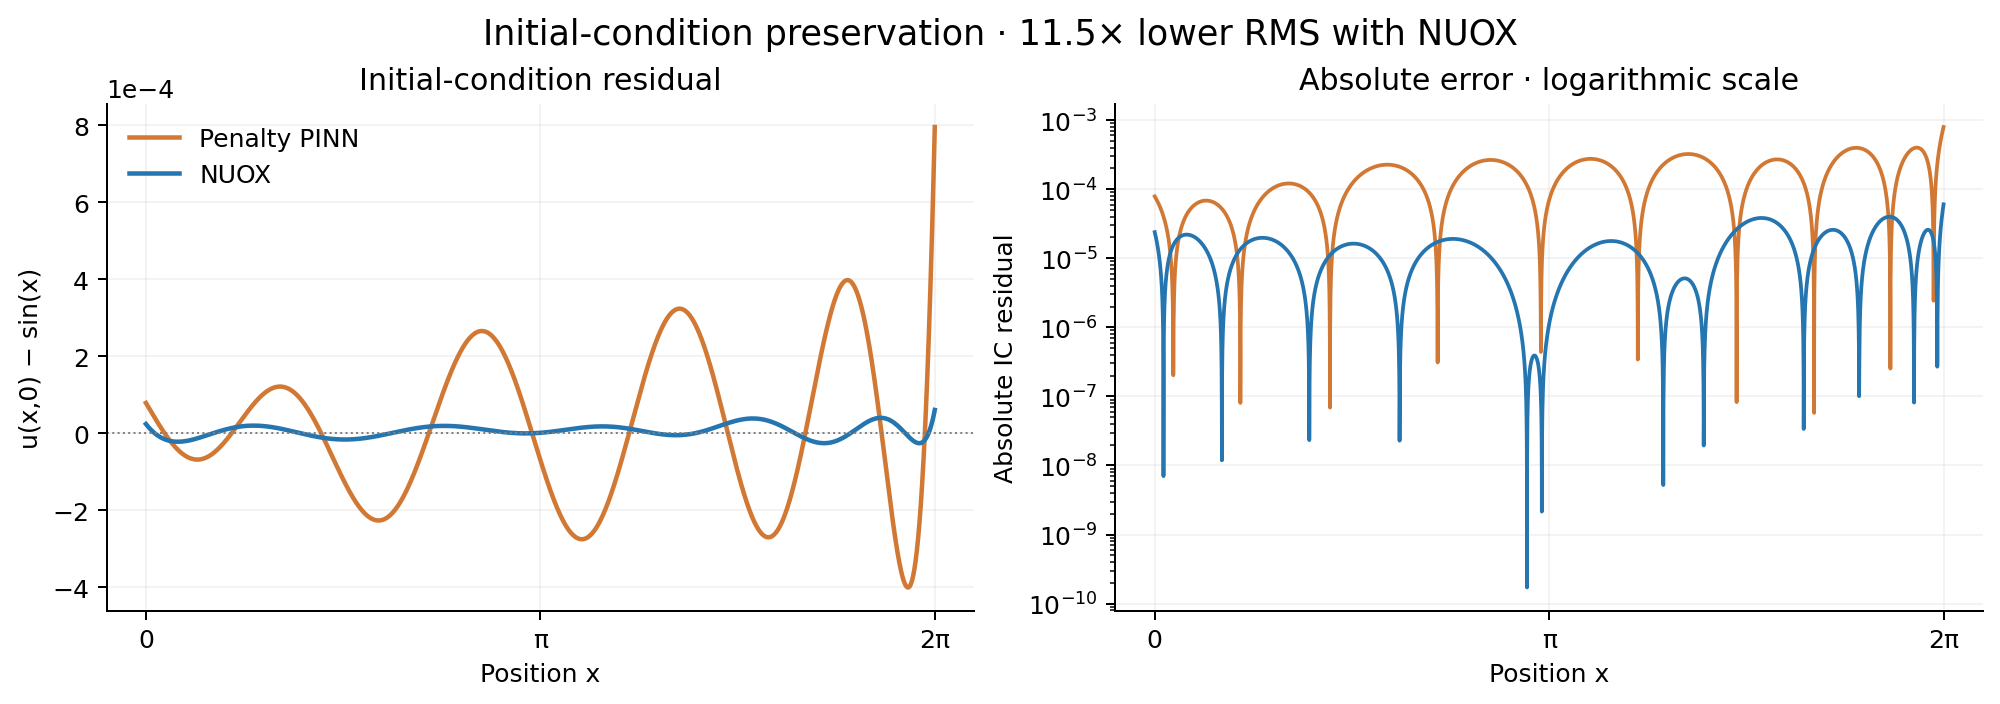

In [ ]:
figures = {"initial_condition": condition_plot(results)}

Now inspect the solution accuracy. The solution heatmaps and absolute-error maps use shared color scales. The training plots include the IC RMS during the final NUOX refinement.

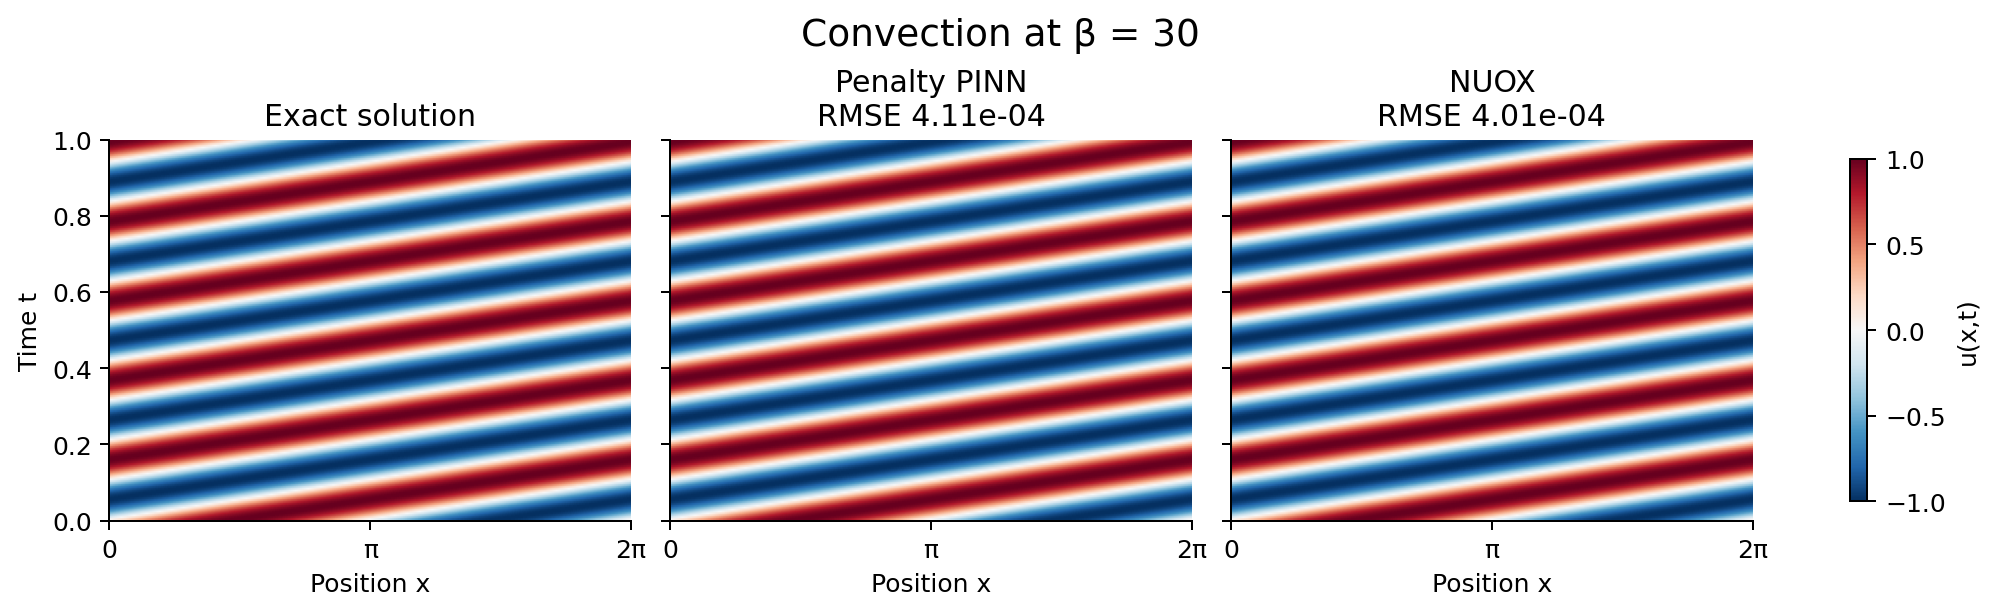

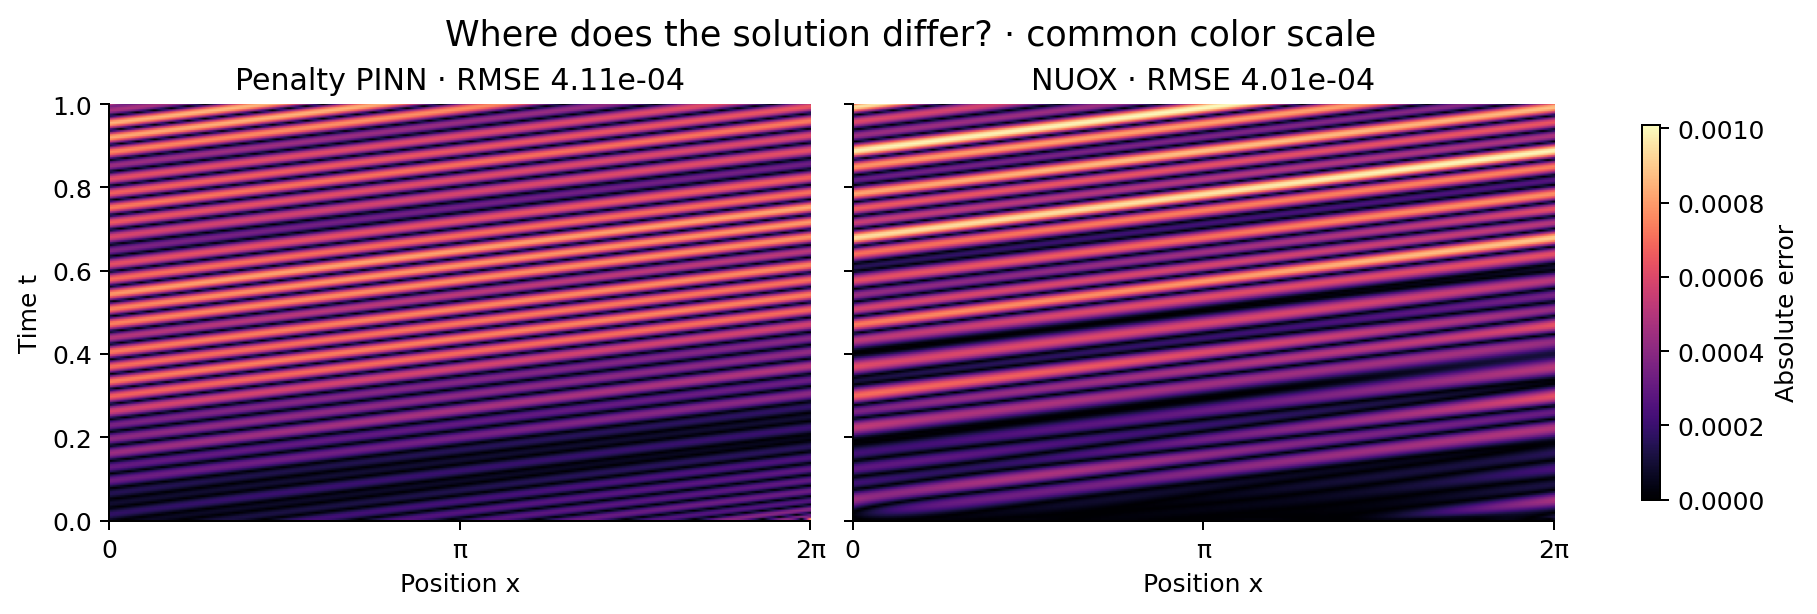

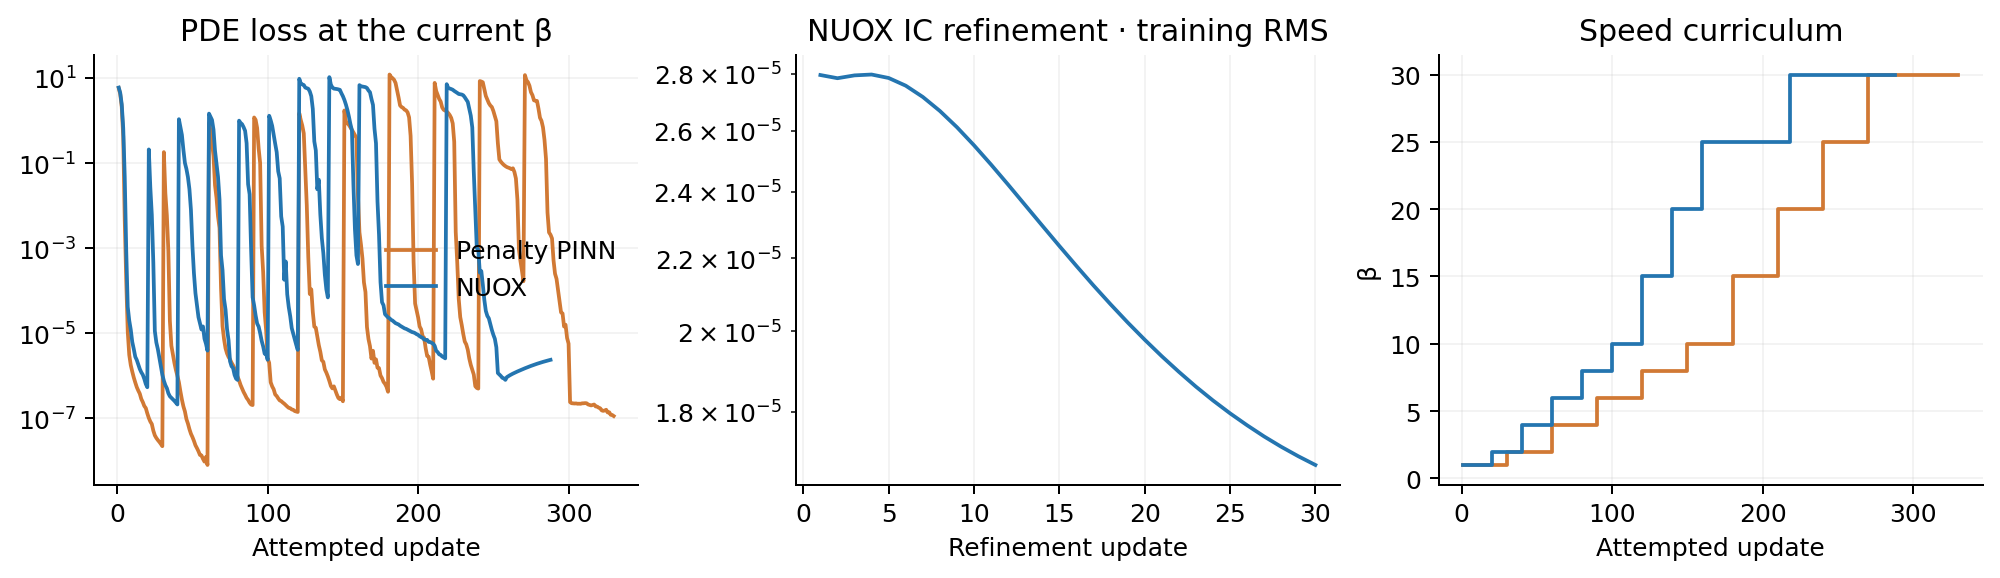

In [ ]:
figures["solution"] = solution_plot(results)
figures["absolute_error"] = error_plot(results)
figures["training"] = training_plot(results)

The PDE-loss jumps coincide with changes in $\beta$. The final 30 updates focus on reducing constraint violations; they increase the PDE residual somewhat while retaining low field error. Finite numerical errors remain: neither a completed schedule nor a small IC residual is a global feasibility guarantee.

## 6. Try it yourself

- Compare `refinement_steps=0` with the default 30 to see the effect of feasibility refinement.
- Change `gamma` to inspect the correction strength.
- Change the initial values and update the exact solution used in `audit` before interpreting field-error scores.

All training starts from the supplied untrained weights. The last cell saves the newly measured results and PNG/PDF figures.

In [ ]:
save_results(results, figures, folder / "results")

Saved measured results and figures to results/
